#Data Science Lifecycle
---
##Case Study: Loan Status
**Objective:**
In this exercise, we will explore a dataset of Loan data with the below info. We will try later to predict the status of loan for individuals based the following information.</font>

## DataSet Description

- **Loan_ID:** data set unique ID <br>
- **Gender:** individual gender<br>
- **Married:** individual marital status<br>
- **Dependents:** number of dependents<br>
- **Education:** individual education status<br>
- **Self_Employed:** individual employment status<br>
- **ApplicantIncome:** individual income<br>
- **CoapplicantIncome:** individual Coapplicant income<br>
- **LoanAmount:** Loan amount in thousands<br>
- **Loan_Amount_Term:** term of loan in months<br>
- **Credit_History:** credit history meets guidelines<br>
- **Property_Area:** Urban/ Semi Urban/ Rural<br>
- **Loan_Status:** loan approved (Y/N)<br>

# 1. Import necessary python modules (libraries)
<br>
We will need the following libraries:

- Numpy — for scientific computing (e.g., linear algebra (vectors & matrices)).
- Pandas — providing high-performance, easy-to-use data reading, manipulation, and analysis.
- Matplotlib & seaborn — plotting & visualization.
- scikit-learn — a tool for data mining and machine learning models. We will need from it the following functions: LabelEncoder, train_test_split, LogisticRegression, and accuracy_score

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 2. Read & visualize data
To load the data to our code, we use pandas module, more specifically, the read_csv function.

Combine the two dataset in order to apply the same preprocessing steps in both dataframes
Don't forget to print the head of your dataset to get a better insight into it.

In [ ]:
# Load the dataset
test_set = pd.read_csv("test.csv")
train_set = pd.read_csv("train.csv")

combined_set = pd.concat([train_set, test_set], axis=0)
print(combined_set.head())
print(combined_set.tail())

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

# 3. Exploratory Data Analysis


Start by getting the number of rows and the number of columns that you have in your dataset

In [ ]:
print(combined_set.shape)

(614, 13)


##### Use the function info(), to check:

- data types (int, float, or object (e.g., string))
- missing values
- memory usage
- number of rows and columns

In [ ]:
print(combined_set.info())

<class 'pandas.core.frame.DataFrame'>
Index: 614 entries, 0 to 100
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 67.2+ KB
None


Where did you find some missing values?     

##### Use the function describe(), to check the following  values for each numerical feature (column)
- mean
- standard deviation
- maximum
- minimum


In [ ]:
print(combined_set.describe())

       ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
count       614.000000         614.000000  592.000000         600.00000   
mean       5403.459283        1621.245798  146.412162         342.00000   
std        6109.041673        2926.248369   85.587325          65.12041   
min         150.000000           0.000000    9.000000          12.00000   
25%        2877.500000           0.000000  100.000000         360.00000   
50%        3812.500000        1188.500000  128.000000         360.00000   
75%        5795.000000        2297.250000  168.000000         360.00000   
max       81000.000000       41667.000000  700.000000         480.00000   

       Credit_History  
count      564.000000  
mean         0.842199  
std          0.364878  
min          0.000000  
25%          1.000000  
50%          1.000000  
75%          1.000000  
max          1.000000  


Print the unique values of the variable Credit_History

In [ ]:
combined_set["Credit_History"].unique()

array([ 1.,  0., nan])

Do the same with the variable Loan_Amount_Term

In [ ]:
combined_set["Loan_Amount_Term"].unique()

array([360., 120., 240.,  nan, 180.,  60., 300., 480.,  36.,  84.,  12.])

##### Use the function describe(include='o'), to check the following  values for each categorical feature:
* count
* unique
* top
* freq


In [ ]:
combined_set.astype({"Credit_History":"str"}).describe(include=["object"])

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Credit_History,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614,614
unique,614,2,2,4,2,2,3,3,2
top,LP001002,Male,Yes,0,Graduate,No,1.0,Semiurban,Y
freq,1,489,398,345,480,500,475,233,422


Interpret the results you obtained for the variable Gender:

####Gender

> count 614;
unique 2;
top male;
freq 489.
>
>This means that for the categorical feature, 'Gender', has 2 unique values, with 'male' the top value having 489 records.

Compute the frequency for each unique value in the categorical feature specified in the code cells below

In [ ]:
combined_set.describe(include=["object"]).loc["freq"]

Loan_ID            1
Gender           489
Married          398
Dependents       345
Education        480
Self_Employed    500
Property_Area    233
Loan_Status      422
Name: freq, dtype: object

Create a new dataframe removeNA_df, where you remove the nulls existing in the original dataframe. This is only for being able to visualize distributions. In a later step, we will be focusing on cleaning our original dataset in a better way

In [ ]:
print(combined_set.isnull().sum(),"\n")
removeNA_df = combined_set.dropna()
print(removeNA_df.isnull().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64 

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


Plot the distribution and the boxplot for the variable 'LoanAmount'

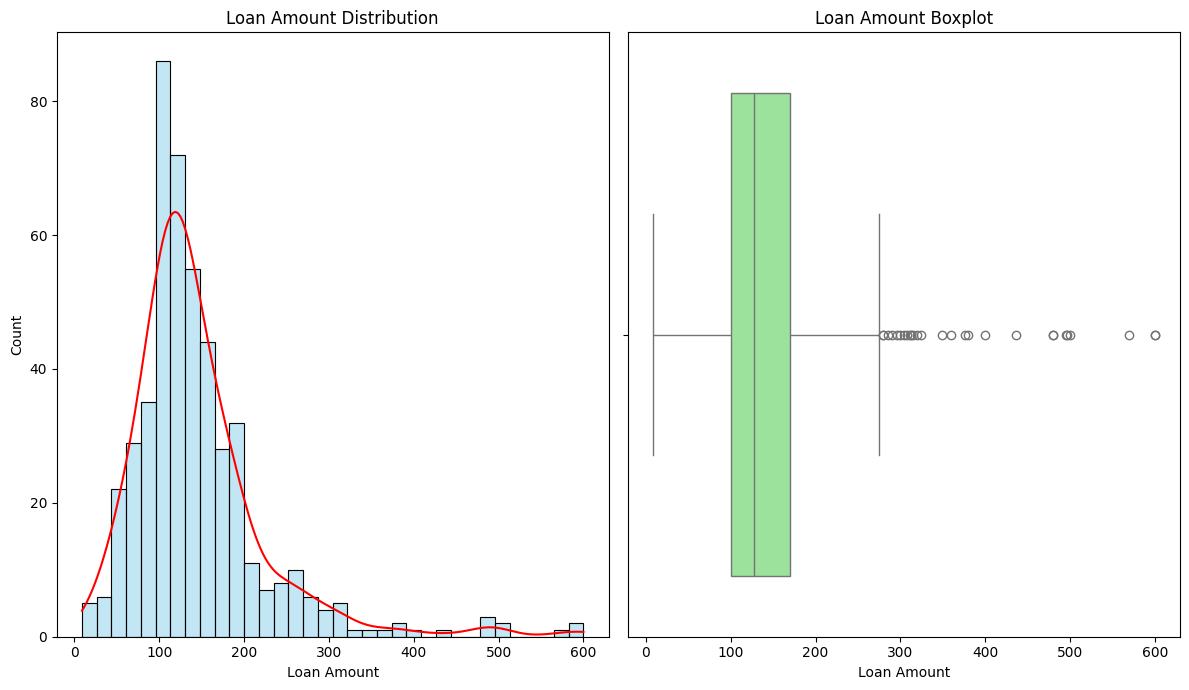

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,7))

sns.histplot(data=removeNA_df, x="LoanAmount", kde= True, ax=axes[0], color="skyblue").lines[0].set_color("red")
axes[0].set_title("Loan Amount Distribution")
axes[0].set_xlabel("Loan Amount")

sns.boxplot(data=removeNA_df, x="LoanAmount", ax= axes[1], color="lightgreen")
axes[1].set_title("Loan Amount Boxplot")
axes[1].set_xlabel("Loan Amount")

plt.tight_layout()
plt.show()


* Is there any outlier?
YESS

* Is the data skewed?
YESS

Do the same for the variable 'ApplicantIncome'

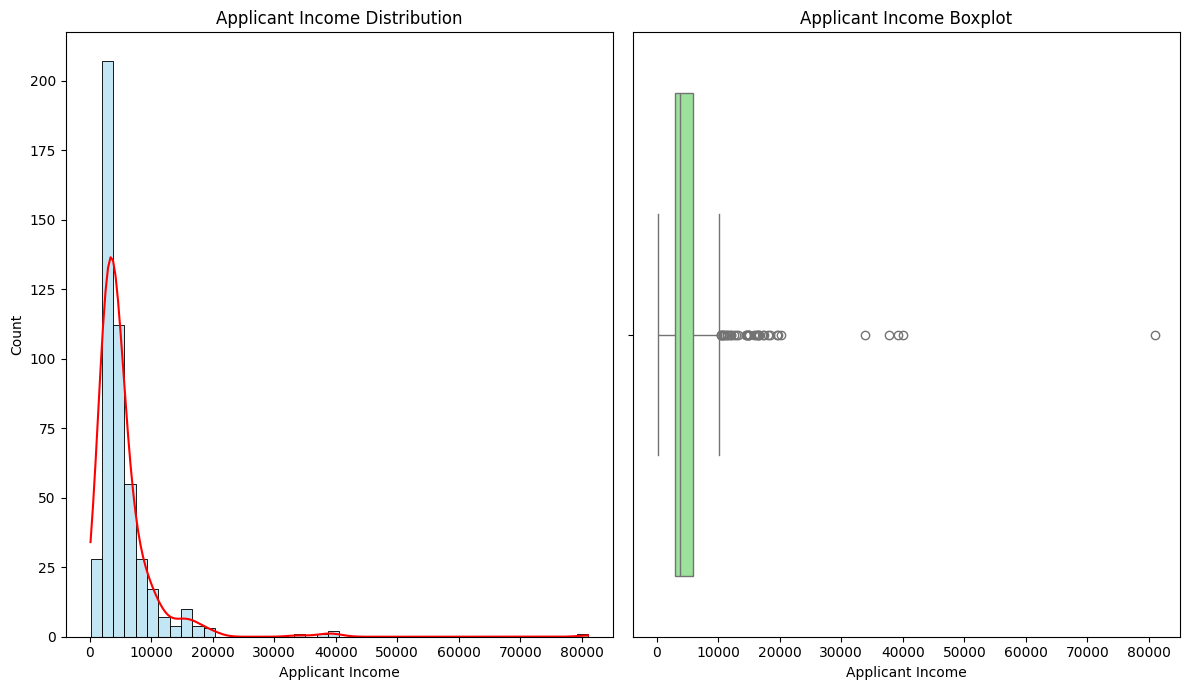

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,7))

sns.histplot(data=removeNA_df, x="ApplicantIncome", kde= True, ax=axes[0], color="skyblue").lines[0].set_color("red")
axes[0].set_title("Applicant Income Distribution")
axes[0].set_xlabel("Applicant Income")

sns.boxplot(data=removeNA_df, x="ApplicantIncome", ax= axes[1], color="lightgreen")
axes[1].set_title("Applicant Income Boxplot")
axes[1].set_xlabel("Applicant Income")

plt.tight_layout()
plt.show()

* Is there any outlier?
> YESS

* Is the data skewed?
> YESS

Do the same for 'CoapplicantIncome'

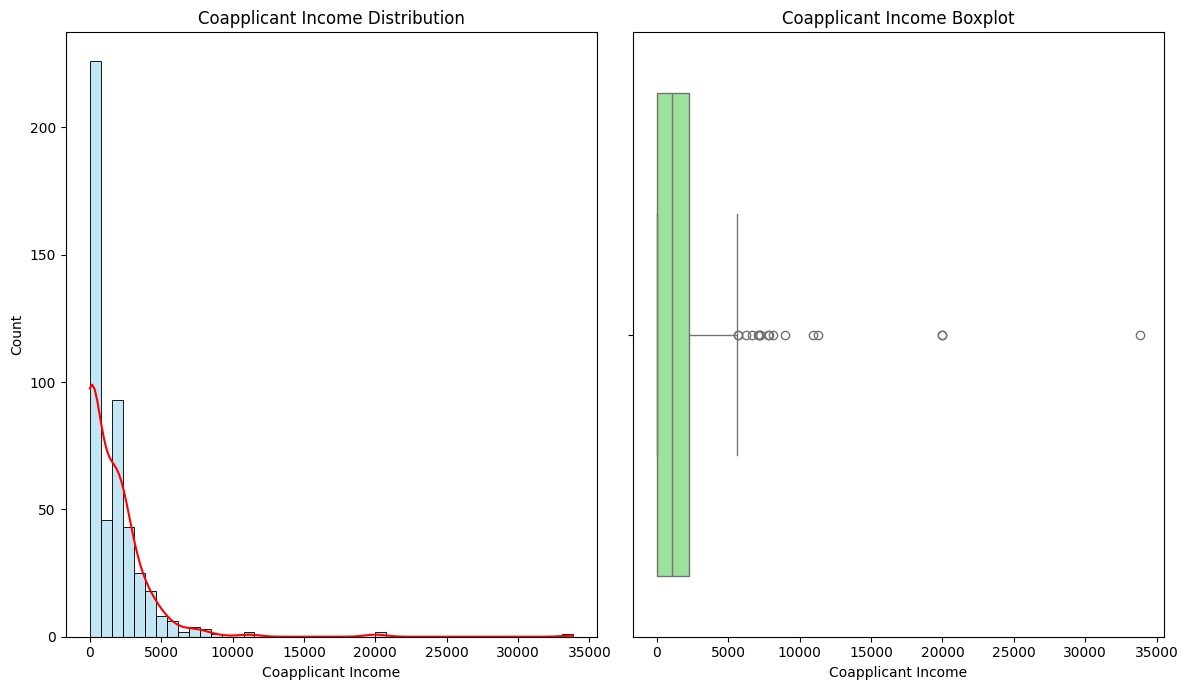

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,7))

sns.histplot(data=removeNA_df, x="CoapplicantIncome", kde= True, ax=axes[0], color="skyblue").lines[0].set_color("red")
axes[0].set_title("Coapplicant Income Distribution")
axes[0].set_xlabel("Coapplicant Income")

sns.boxplot(data=removeNA_df, x="CoapplicantIncome", ax= axes[1], color="lightgreen")
axes[1].set_title("Coapplicant Income Boxplot")
axes[1].set_xlabel("Coapplicant Income")

plt.tight_layout()
plt.show()

Do the same for 'Loan_Amount_Term'

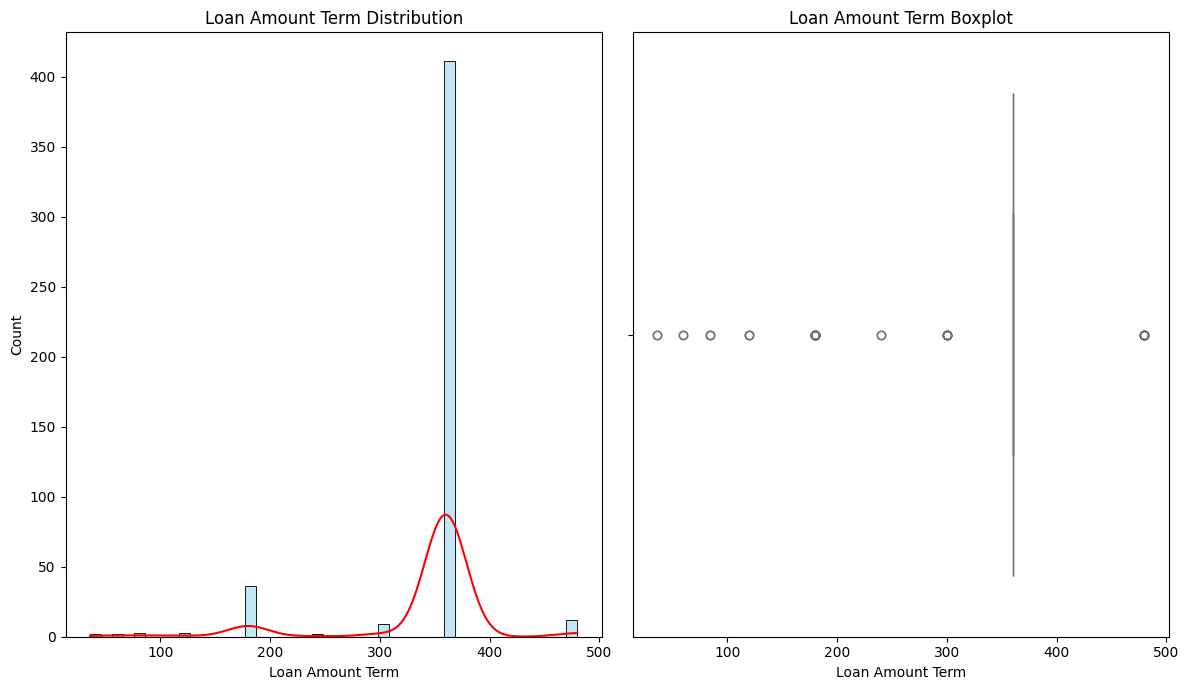

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,7))

sns.histplot(data=removeNA_df, x="Loan_Amount_Term", kde= True, ax=axes[0], color="skyblue").lines[0].set_color("red")
axes[0].set_title("Loan Amount Term Distribution")
axes[0].set_xlabel("Loan Amount Term")

sns.boxplot(data=removeNA_df, x="Loan_Amount_Term", ax= axes[1], color="lightgreen")
axes[1].set_title("Loan Amount Term Boxplot")
axes[1].set_xlabel("Loan Amount Term")

plt.tight_layout()
plt.show()

What do you think about outliers in this case?

> In this case, the Loan_Amount_Term this is a set of discrete loan durations, not a continuous measurement. A boxplot may flag uncommon terms—such as very short or long durations—as outliers even when they’re legitimate products. I’d inspect their counts and treat the term as categorical or discrete.

So the plots are useful signals to investigate, but an IQR-based outlier label alone isn’t evidence of bad data.



Plot the value_counts for 'Loan_Amount_Term'

Do the same for the categorical variables you have ('Dependants', 'Education', etc), using a subplot of size 4 by 2

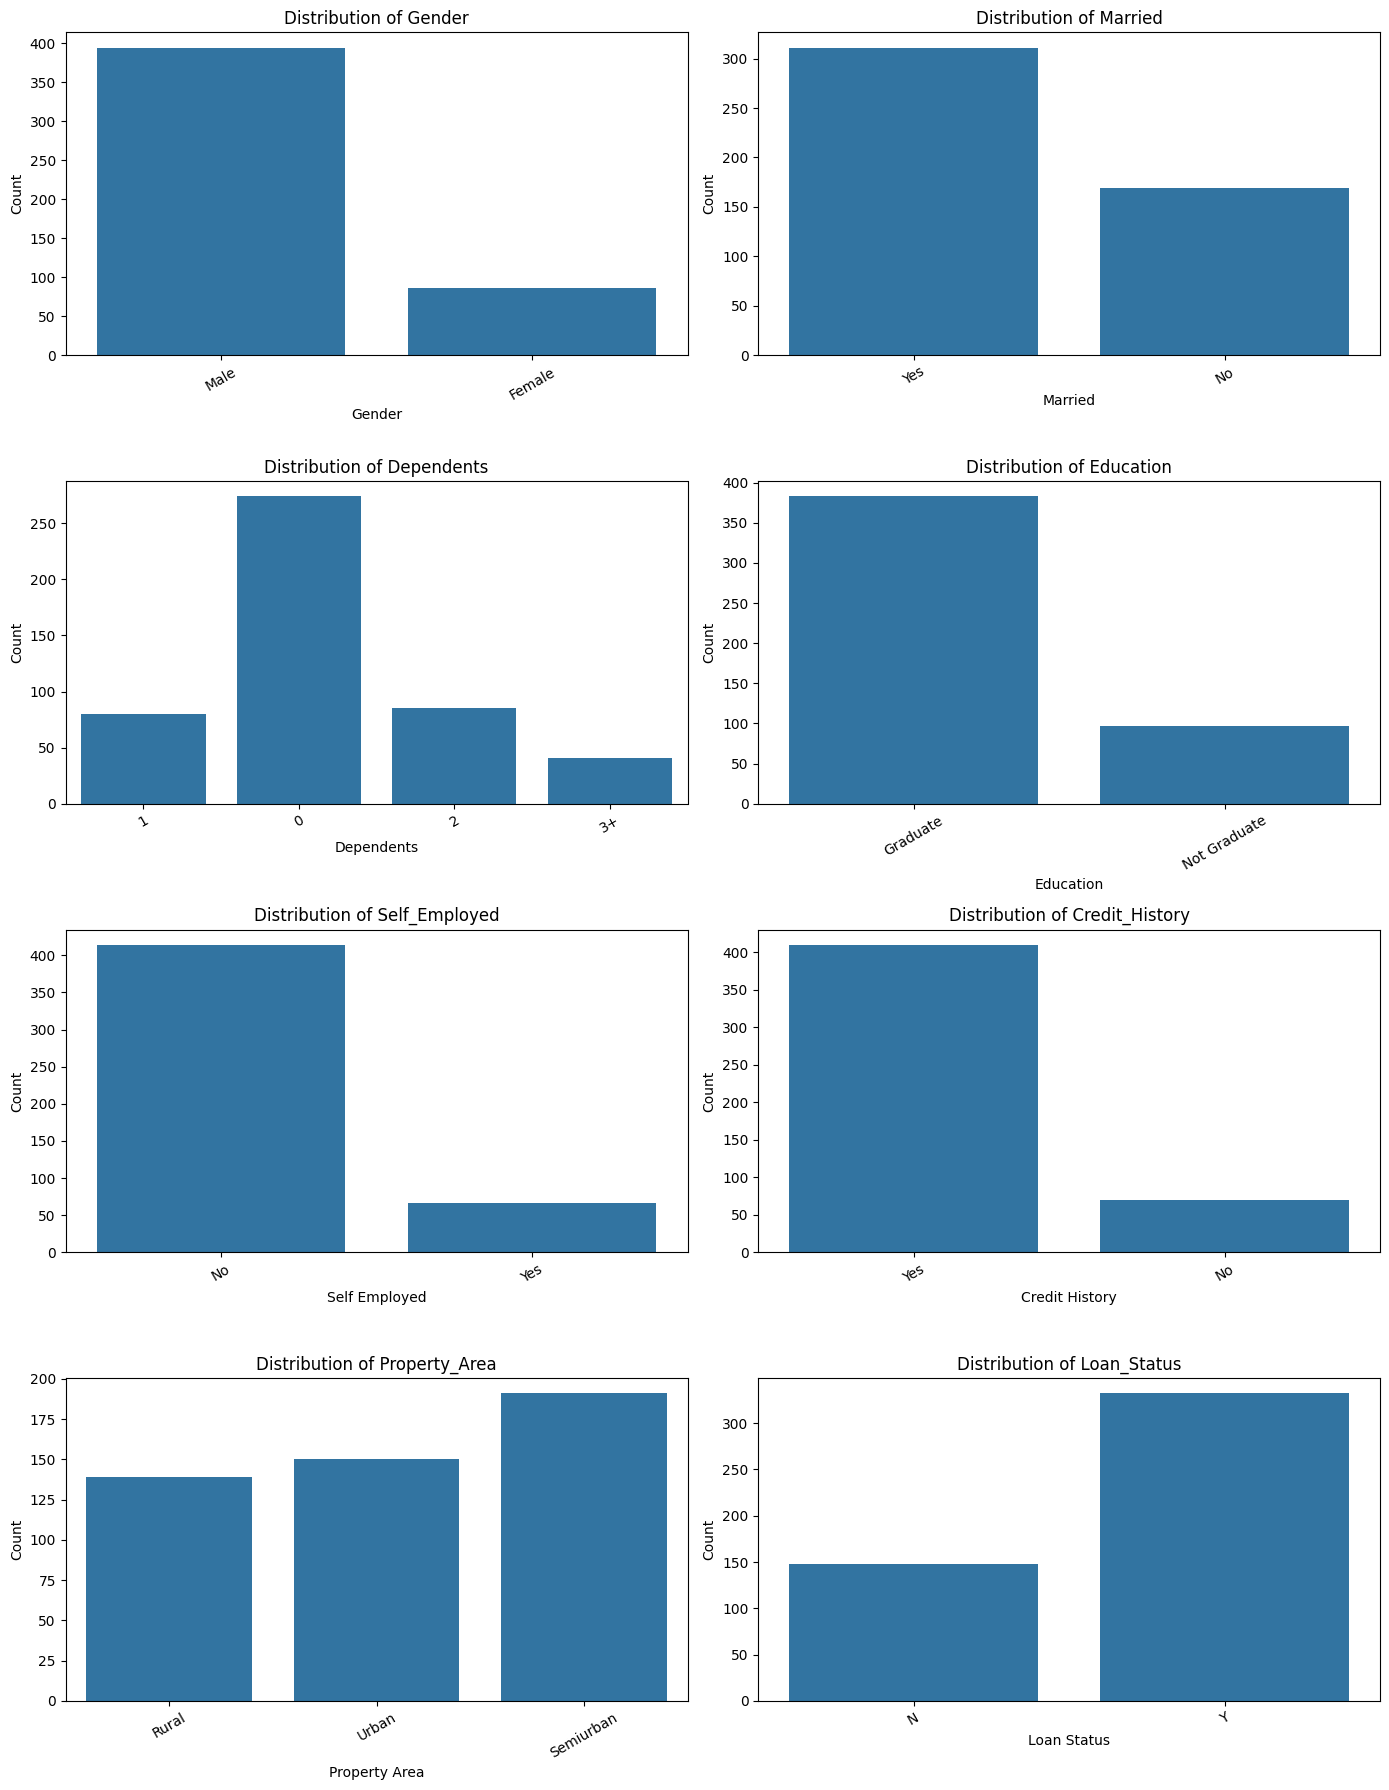

In [ ]:
plot_df = removeNA_df.copy()
plot_df["Credit_History"] = plot_df["Credit_History"].map({1.0: "Yes", 0.0: "No"})

columns = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Credit_History",
    "Property_Area",
    "Loan_Status"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for ax, column in zip(axes, columns):
    sns.countplot(data=plot_df, x=column, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column.replace("_", " "))
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Perform CrossTabing between Gender and Loan_Status, and then plot the acceptance/rejection of loans for different Genders

Loan_Status,Rejected,Accepted
Gender,,
Female,32,54
Male,116,278


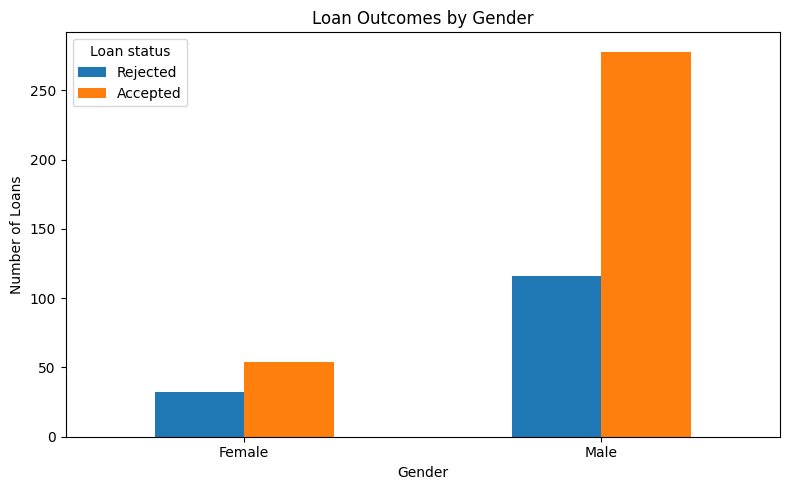

In [ ]:
loan_counts = pd.crosstab(plot_df["Gender"], plot_df["Loan_Status"])
loan_counts = loan_counts.rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_counts)

loan_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcomes by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Loan_Status,Rejected,Accepted
Gender,,
Female,37.2,62.8
Male,29.4,70.6


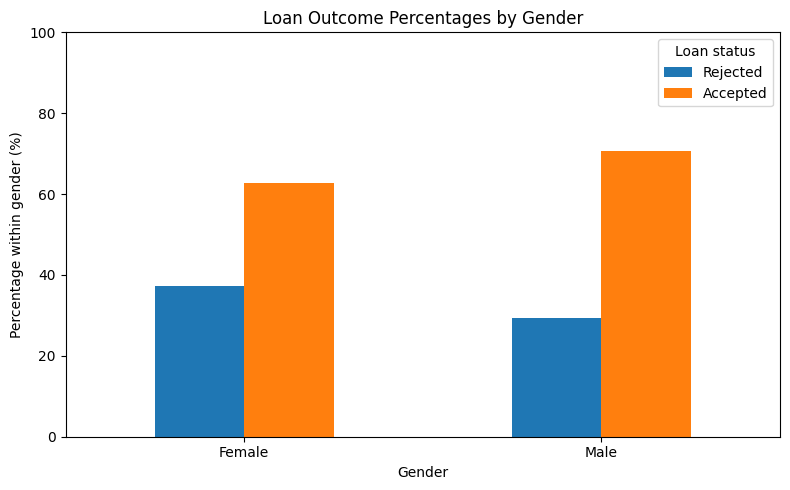

In [ ]:
loan_percentages = (
    pd.crosstab(plot_df["Gender"], plot_df["Loan_Status"], normalize="index") * 100
).rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_percentages.round(1))

loan_percentages.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcome Percentages by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage within gender (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Does the Gender affect the acceptance of the Loan?
> not really






Do the same with Credit_History and Loan_Status

Loan_Status,Rejected,Accepted
Credit_History,,
No,63,7
Yes,85,325


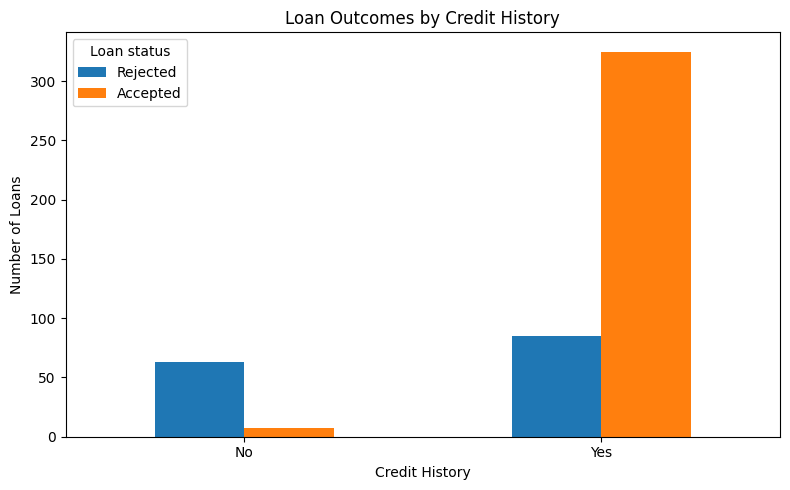

In [ ]:
loan_credit_hist_plt = pd.crosstab(plot_df["Credit_History"], plot_df["Loan_Status"])
loan_credit_hist_plt = loan_credit_hist_plt.rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_credit_hist_plt)

loan_credit_hist_plt.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcomes by Credit History")
plt.xlabel("Credit History")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Loan_Status,Rejected,Accepted
Credit_History,,
No,90.0,10.0
Yes,20.7,79.3


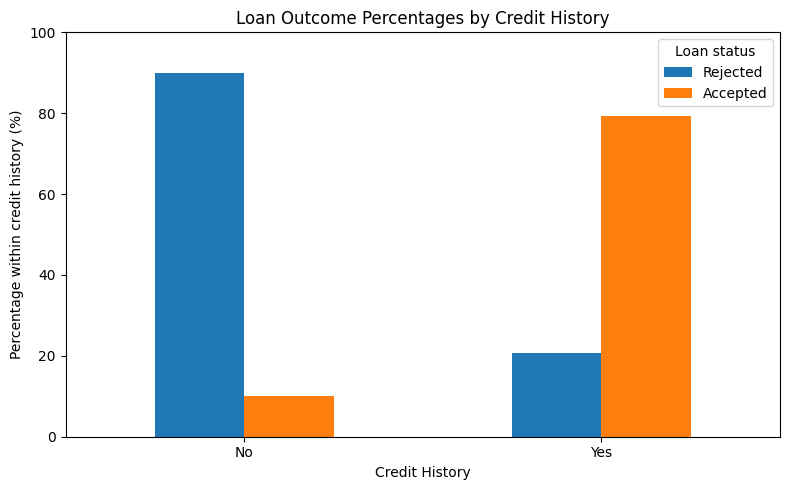

In [ ]:
loan_credit_hist_percentages = (
    pd.crosstab(plot_df["Credit_History"], plot_df["Loan_Status"], normalize="index") * 100
).rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_credit_hist_percentages.round(1))

loan_credit_hist_percentages.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcome Percentages by Credit History")
plt.xlabel("Credit History")
plt.ylabel("Percentage within credit history (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Does the Credit History affect the acceptance of the Loan?

Having a qualifying credit history may have a higher probability of their loan being accepted but that only means they have an association

Do the same with Dependents and Loan_Status

Loan_Status,Rejected,Accepted
Dependents,,
0,87,187
1,28,52
2,20,65
3+,13,28


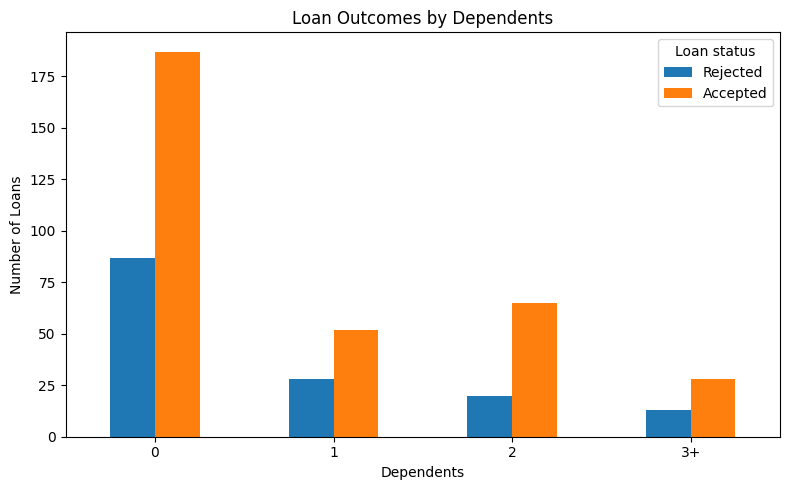

In [ ]:
loan_dependents_plt = pd.crosstab(plot_df["Dependents"], plot_df["Loan_Status"])
loan_dependents_plt = loan_dependents_plt.rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_dependents_plt)

loan_dependents_plt.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcomes by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Loan_Status,Rejected,Accepted
Dependents,,
0,31.8,68.2
1,35.0,65.0
2,23.5,76.5
3+,31.7,68.3


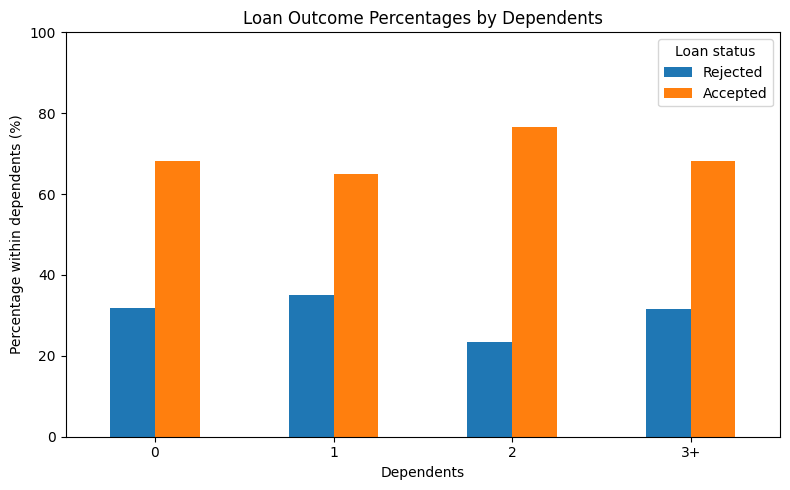

In [ ]:
loan_dependents_percentages = (
    pd.crosstab(plot_df["Dependents"], plot_df["Loan_Status"], normalize="index") * 100
).rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_dependents_percentages.round(1))

loan_dependents_percentages.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcome Percentages by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Percentage within dependents (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Does the number of dependents affect the acceptance of the Loan?

Slight to no association

Do the same between Education and Loan_Status

Loan_Status,Rejected,Accepted
Education,,
Graduate,112,271
Not Graduate,36,61


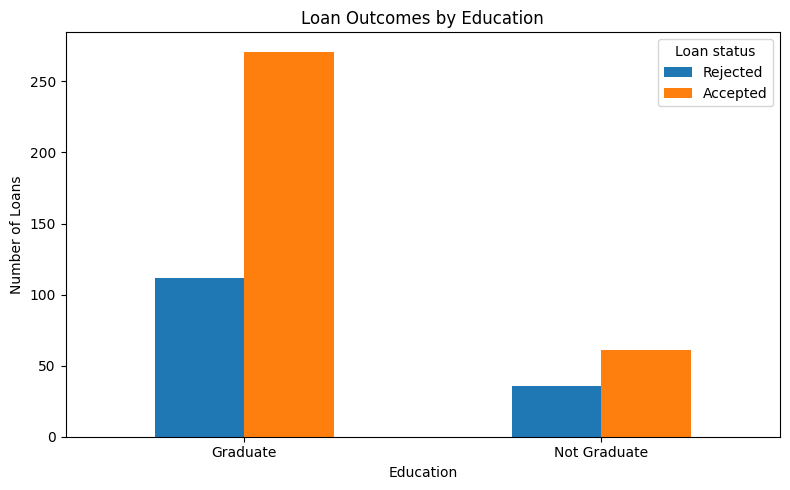

In [ ]:
loan_education_plt = pd.crosstab(plot_df["Education"], plot_df["Loan_Status"])
loan_education_plt = loan_education_plt.rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_education_plt)

loan_education_plt.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcomes by Education")
plt.xlabel("Education")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Loan_Status,Rejected,Accepted
Education,,
Graduate,29.2,70.8
Not Graduate,37.1,62.9


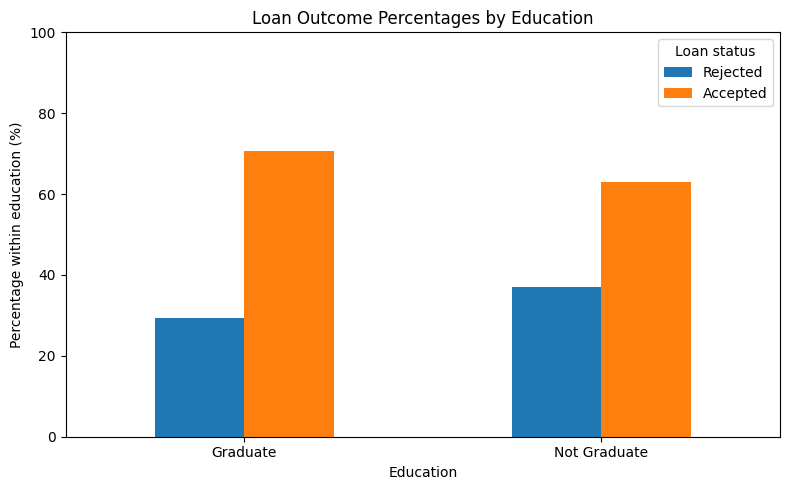

In [ ]:
loan_education_percentages = (
    pd.crosstab(plot_df["Education"], plot_df["Loan_Status"], normalize="index") * 100
).rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_education_percentages.round(1))

loan_education_percentages.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcome Percentages by Education")
plt.xlabel("Education")
plt.ylabel("Percentage within education (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Does the level of education affect the acceptance of the Loan?

Some association

Do the same between Married and Loan_Status

Loan_Status,Rejected,Accepted
Married,,
No,64,105
Yes,84,227


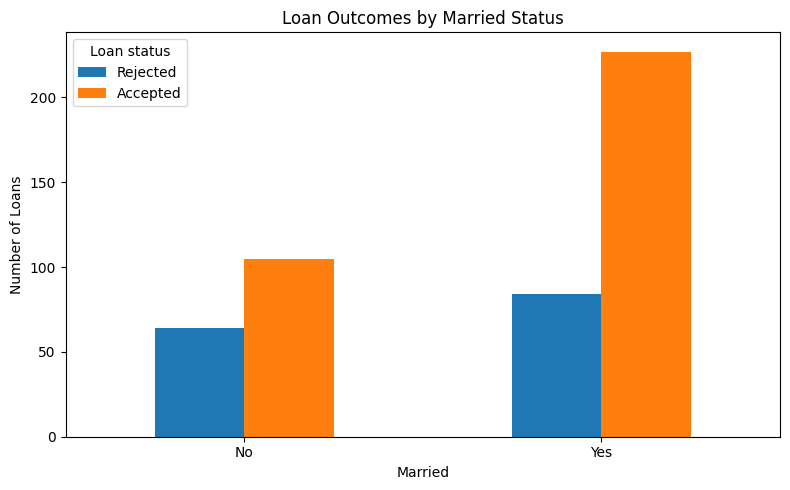

In [ ]:
loan_married_plt = pd.crosstab(plot_df["Married"], plot_df["Loan_Status"])
loan_married_plt = loan_married_plt.rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_married_plt)

loan_married_plt.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcomes by Married Status")
plt.xlabel("Married")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Loan_Status,Rejected,Accepted
Married,,
No,37.9,62.1
Yes,27.0,73.0


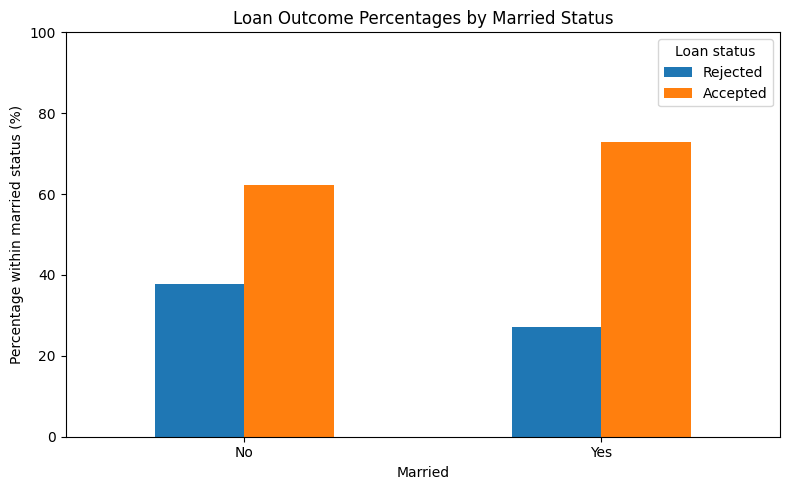

In [ ]:
loan_married_percentages = (
    pd.crosstab(plot_df["Married"], plot_df["Loan_Status"], normalize="index") * 100
).rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_married_percentages.round(1))

loan_married_percentages.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcome Percentages by Married Status")
plt.xlabel("Married")
plt.ylabel("Percentage within married status (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Does the marriage affect the acceptance of the Loan?

Some association

Do the same between Property_Area and Loan_Status

Loan_Status,Rejected,Accepted
Property_Area,,
Rural,54,85
Semiurban,42,149
Urban,52,98


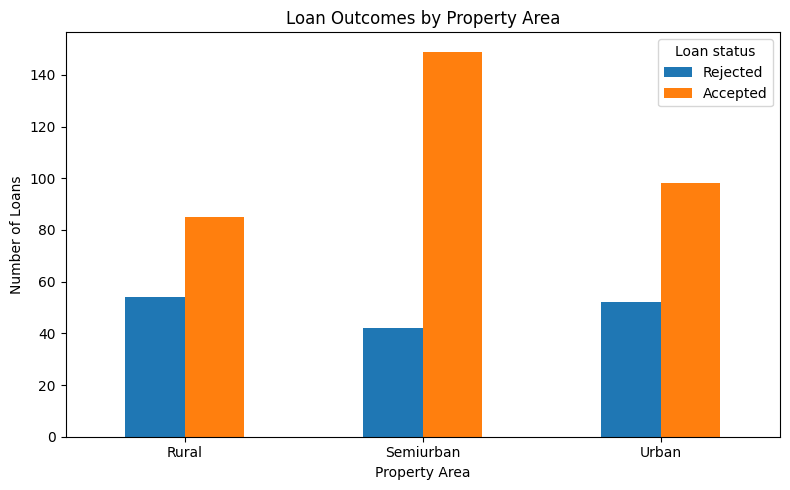

In [ ]:
loan_property_area_plt = pd.crosstab(plot_df["Property_Area"], plot_df["Loan_Status"])
loan_property_area_plt = loan_property_area_plt.rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_property_area_plt)

loan_property_area_plt.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcomes by Property Area")
plt.xlabel("Property Area")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Loan_Status,Rejected,Accepted
Property_Area,,
Rural,38.8,61.2
Semiurban,22.0,78.0
Urban,34.7,65.3


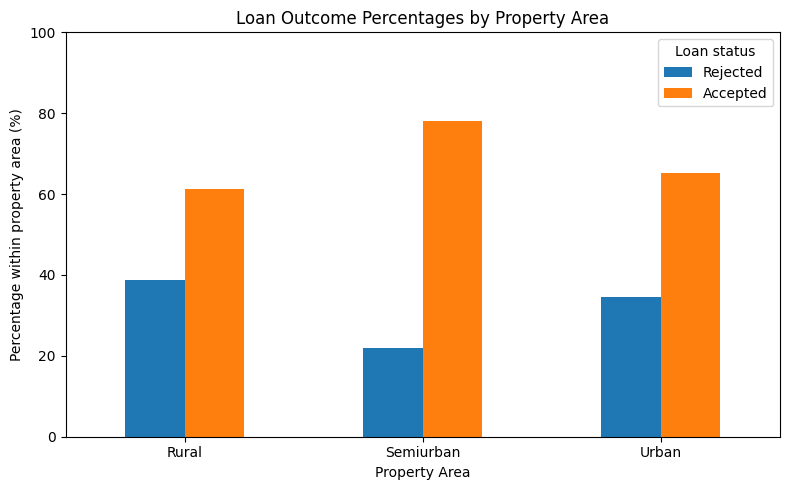

In [ ]:
loan_property_area_percentages = (
    pd.crosstab(plot_df["Property_Area"], plot_df["Loan_Status"], normalize="index") * 100
).rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_property_area_percentages.round(1))

loan_property_area_percentages.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcome Percentages by Property Area")
plt.xlabel("Property Area")
plt.ylabel("Percentage within property area (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Does the Property Area affect the acceptance of the Loan?

Noticeable Association

Do the same between Self_Employed and Loan_Status

Loan_Status,Rejected,Accepted
Self_Employed,,
No,125,289
Yes,23,43


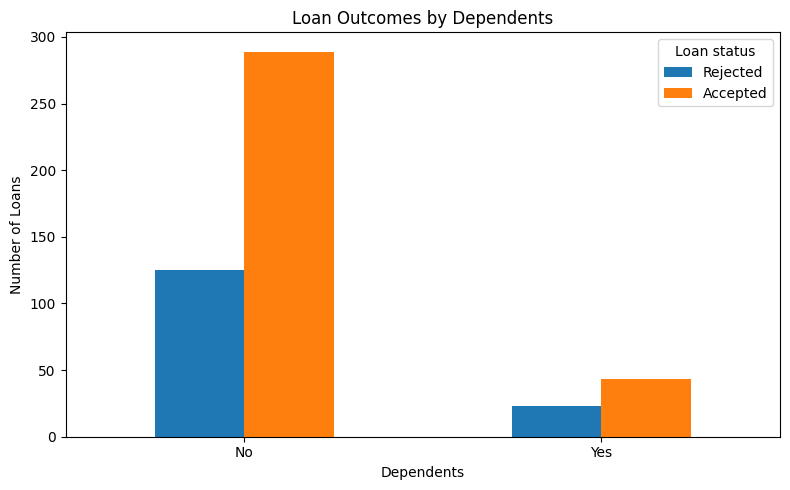

In [ ]:
loan_self_employed_plt = pd.crosstab(plot_df["Self_Employed"], plot_df["Loan_Status"])
loan_self_employed_plt = loan_self_employed_plt.rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_self_employed_plt)

loan_self_employed_plt.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcomes by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Loan_Status,Rejected,Accepted
Self_Employed,,
No,30.2,69.8
Yes,34.8,65.2


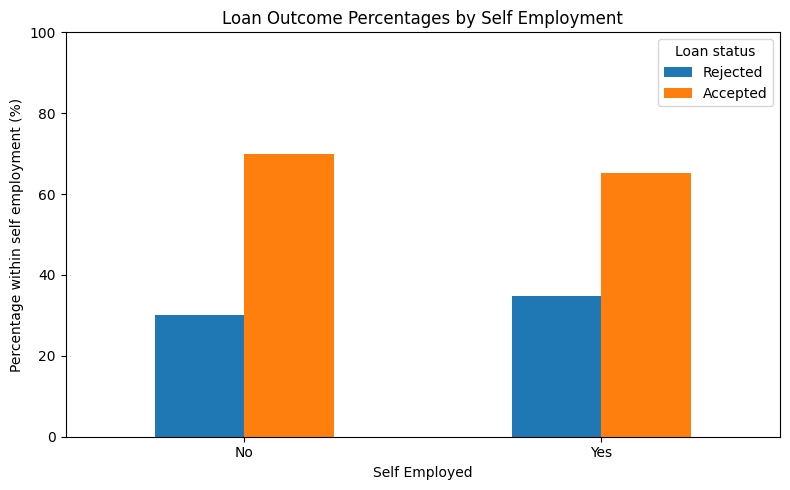

In [ ]:
loan_self_employed_percentages = (
    pd.crosstab(plot_df["Self_Employed"], plot_df["Loan_Status"], normalize="index") * 100
).rename(columns={"Y": "Accepted", "N": "Rejected"})

display(loan_self_employed_percentages.round(1))

loan_self_employed_percentages.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Outcome Percentages by Self Employment")
plt.xlabel("Self Employed")
plt.ylabel("Percentage within self employment (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Loan status")
plt.tight_layout()
plt.show()

Does the Self Employed Property affect the acceptance of the Loan?

Little Association

Plot a Scatter Plot between Loan_Status and:
* ApplicantIncome
* CoapplicantIncome
* LoanAmount
* LoanAmount_Term

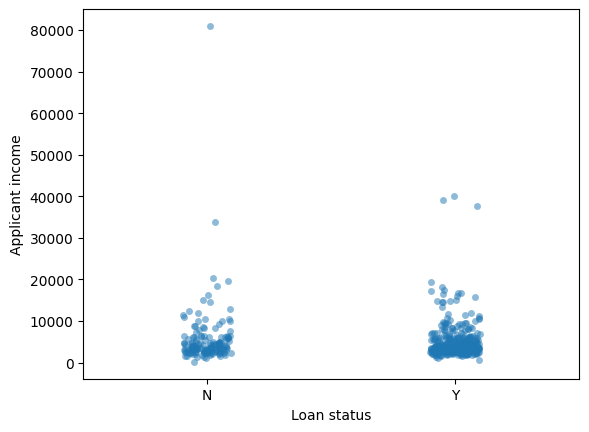

In [ ]:
sns.stripplot(data=plot_df, x="Loan_Status", y="ApplicantIncome", jitter=True, alpha=0.5)
plt.xlabel("Loan status")
plt.ylabel("Applicant income")
plt.show()

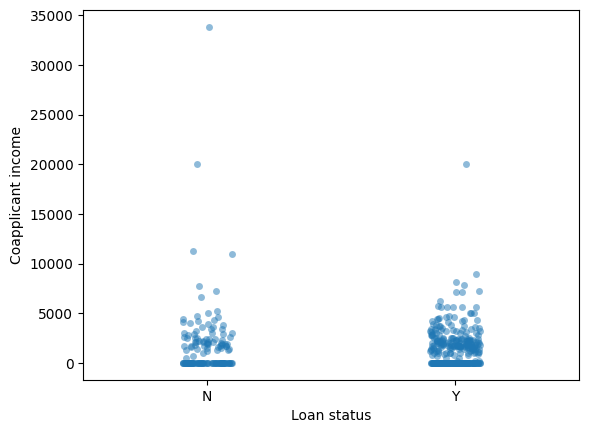

In [ ]:
sns.stripplot(data=plot_df, x="Loan_Status", y="CoapplicantIncome", jitter=True, alpha=0.5)
plt.xlabel("Loan status")
plt.ylabel("Coapplicant income")
plt.show()

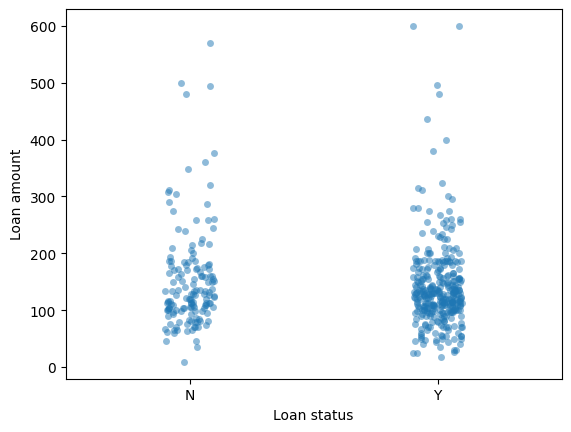

In [ ]:
sns.stripplot(data=plot_df, x="Loan_Status", y="LoanAmount", jitter=True, alpha=0.5)
plt.xlabel("Loan status")
plt.ylabel("Loan amount")
plt.show()

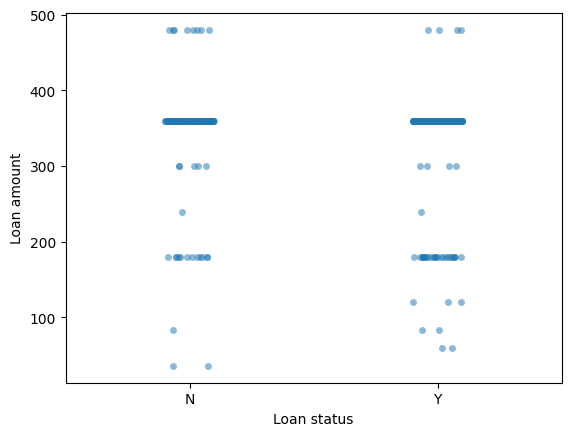

In [ ]:
sns.stripplot(data=plot_df, x="Loan_Status", y="Loan_Amount_Term", jitter=True, alpha=0.5)
plt.xlabel("Loan status")
plt.ylabel("Loan amount")
plt.show()

Do you think these scatter plots gave you valuable information about the Loan_Status?

Yes, the plots are useful for an initial visual check, but they don’t show a strong, clear separation between approved and rejected loans

Group your dataframe by Loan_Status on the median Value

In [ ]:
numeric_cols = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

plot_df.groupby("Loan_Status")[numeric_cols].median()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
Loan_Status,,,,
N,3871.0,0.0,128.0,360.0
Y,3858.5,1211.5,128.0,360.0


What did you deduce?



# 4. Preprocessing
"Garbage in, garbage out".
<br>
<br>
Data should be preprocessed and cleaned to get rid of noisy data. Preprocessing includes:

- remove unsued column(s)
- remove grabage data
- convert continous data into categorical
- treat missing data
- encode categorical data
- normalization: standarize data ranges for all features (e.g., between 0 and 1)

## Remove unused columns

Remove the features that do not contribute to the prediction of the loan status

In [ ]:
train_processed = train_set.drop(columns=["Loan_ID"]).copy()
test_processed = test_set.drop(columns=["Loan_ID"]).copy()

## Remove grabage data

If you go back to one of the EDA steps where you saw the unique values of Dependents, you can see that you have '3+' as a value. In order to make the algorithm learn from such information, you have to replace this with a number. We will replace it by 3.

##Convert continuous data into categorical

Search for the feature that is contionuous but should be categorical and convert it

## Treat missing data
- fill missing categorical data & discrete data with mode
- fill missing continuous data with mean


## Check if any null value exist

## Encode categorical data

Go over your categorical features and encode them (change their values to be numerical to be able to feed them to an algorithm and get a model in the end)

## Normalization

Normalize data ranges for all features (e.g., between 0 and 1)
First compute the maximum of each feature, and then divide each column by its maximum. After it, describe the data

# 6. Training & Validating

Create a variable x for the inputs (Fetaures), and a variable y for the output ('Loan_Status')
Then, split the data between training (70%) and testing (30%).

##Creating & Fitting the model

Create a Logistic Regression Model, and fit it on the training data you have

##Validating the model

Validate your model on the testing data, and compute the accuracy score of your predictions

7. Feature Importance

Evaluate the feature importance in your resulting model, and plot it

What's the most important feature?


